# Semantic segmentation — look at your data first

Most failed projects fail here, not in the model. Before training anything, answer:
1. **How much of the data is each class?** (a tiny object class next to a huge background is the usual problem)
2. **Are masks the right size, and aligned with their images?**
3. **Is the class id numbering what you expect?** (`classes.txt`, and 255 for "ignore")

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/segmentation/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("segmentation", cfg)
print("task:", "segmentation", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: segmentation | data: data/demo/segmentation | outputs: outputs/segmentation_quick


## How the data is organised
An `images/` folder, a `masks/` folder with a same-named single-channel PNG per image where **each pixel's value is its class id**, and `classes.txt` (line *n* names class id *n − 1*; pixels with 255 are ignored). Image and mask are always transformed *together*.

## How many pixels does each class get?
This chart decides your loss function. A class with 1% of pixels is easily ignored by plain cross-entropy — hence the Dice term in the loss.

classes: {0: 'background', 1: 'circle', 2: 'square', 3: 'triangle'}


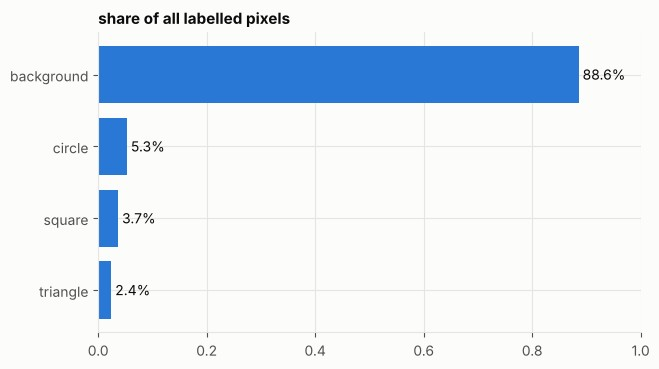

NOTE: one class holds >80% of pixels. Accuracy will look great even for a useless model; judge by per-class IoU.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from cvkit.viz import BLUE, image_grid, overlay_label_map
from tasks.segmentation.data import build_datasets, read_mask

ds = build_datasets(cfg)
classes, pairs = ds["classes"], ds["pairs"]
print("classes:", dict(enumerate(classes)))

counts = np.zeros(len(classes))
for _, mask_path in pairs:
    m = read_mask(mask_path).numpy()
    counts += np.bincount(m[m < len(classes)].ravel(), minlength=len(classes))
share = counts / counts.sum()
fig, ax = plt.subplots(figsize=(7, 0.6 * len(classes) + 1.5))
ax.barh(classes, share, color=BLUE); ax.invert_yaxis(); ax.set_xlim(0, 1)
for i, s in enumerate(share):
    ax.text(s, i, f" {s:.1%}", va="center")
ax.set_title("share of all labelled pixels")
plt.show()
if share.max() > 0.8:
    print("NOTE: one class holds >80% of pixels. Accuracy will look great even for a useless model; judge by per-class IoU.")

## Do masks line up with the images, and do sizes agree?

In [4]:
bad = []
for img_path, mask_path in pairs:
    with Image.open(img_path) as im, Image.open(mask_path) as mk:
        if im.size != mk.size:
            bad.append((Path(img_path).name, im.size, mk.size))
print(f"{len(pairs)} image/mask pairs; {len(bad)} with mismatched sizes", bad[:3])
print("(mismatched sizes are resized independently - they must be the same shape in the first place)" if bad else "all pairs have matching sizes")

300 image/mask pairs; 0 with mismatched sizes []
all pairs have matching sizes


## Augmentation
Image and mask go through the **same** random transform: a flipped image must come with a flipped mask. Masks are resized with *nearest-neighbour* so class ids are never blended into meaningless in-between values.

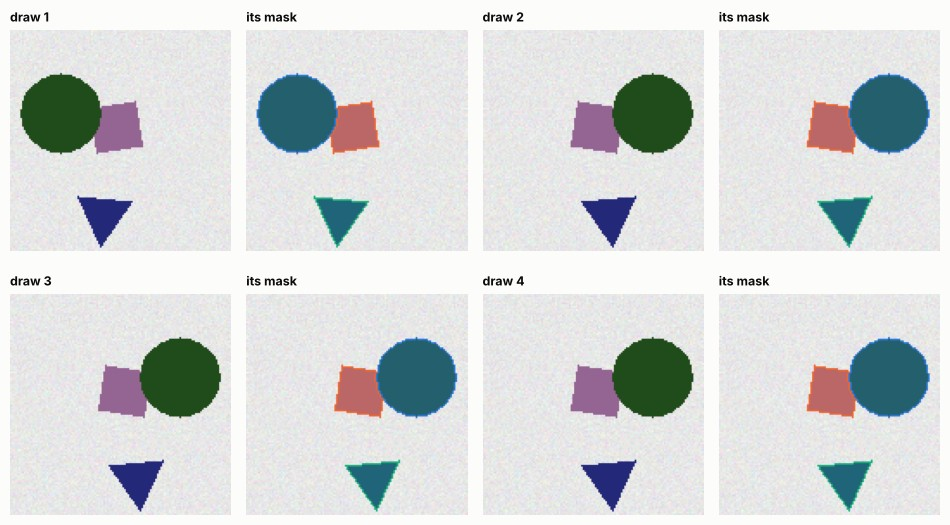

In [5]:
import torch
from cvkit.data import denormalize
from cvkit.viz import image_grid, overlay_label_map
from torchvision.transforms.functional import to_pil_image

train_ds = ds["train"]
shown, titles = [], []
for i in range(4):
    img, mask = train_ds[0]                      # same sample, fresh random augmentation
    pil = to_pil_image(denormalize(img).permute(2, 0, 1))
    shown += [pil, overlay_label_map(pil, mask.numpy().astype("uint8"))]
    titles += [f"draw {i + 1}", "its mask"]
_ = image_grid(shown, titles, cols=4, cell=2.4)

## What the model will actually receive
One batch from the training loader, exactly as `train()` gets it:

In [6]:
from tasks.segmentation.data import build_loaders

loaders = build_loaders(cfg)
images, masks = next(iter(loaders["train"]))
print("images:", tuple(images.shape), images.dtype, "| masks:", tuple(masks.shape), masks.dtype, "(one class id per pixel)")
print("class ids in this batch:", sorted(masks.unique().tolist()))

images: (16, 3, 128, 128) torch.float32 | masks: (16, 128, 128) torch.int64 (one class id per pixel)
class ids in this batch: [0, 1, 2, 3]


## Before moving on
- [ ] Image/mask pairs line up and have the same size
- [ ] `classes.txt` matches the ids actually used in the masks
- [ ] You know which classes are rare, and kept `train.dice_weight` > 0 if one is tiny
- [ ] Unlabelled areas are marked 255, not 0

Next: **[02_train_and_evaluate](02_train_and_evaluate.ipynb)**.